<a href="https://colab.research.google.com/github/nasif-raihan/GSU/blob/main/CSCI_7090_Module_9_Lab_ObjectDetectionBasics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 9 — Object Detection Fundamentals (Lab)
**Computer Vision · Object Detection**

The building blocks every detector (SSD, YOLO, Faster R-CNN) relies on — **bounding boxes**, **IoU**, **anchor boxes**, and **Non-Maximum Suppression** — implemented from scratch with NumPy. Runs anywhere, no downloads.

## 1. Bounding boxes & the two coordinate formats
Detectors use **corner** format `(x_min, y_min, x_max, y_max)` and **center** format `(cx, cy, w, h)`. Let's draw a box and convert between them.

corner: [ 50  40 180 200] -> center: [115. 120. 130. 160.]
round-trip: [ 50.  40. 180. 200.]


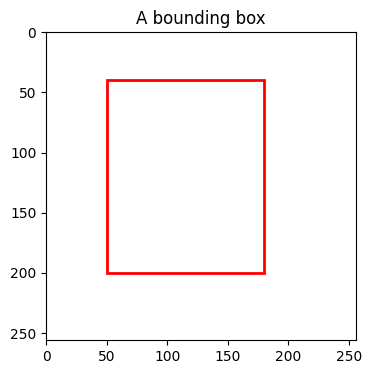

In [1]:
import numpy as np, matplotlib.pyplot as plt
import matplotlib.patches as patches

def corner_to_center(b):
    x1,y1,x2,y2 = b
    return np.array([(x1+x2)/2, (y1+y2)/2, x2-x1, y2-y1])
def center_to_corner(b):
    cx,cy,w,h = b
    return np.array([cx-w/2, cy-h/2, cx+w/2, cy+h/2])

box = np.array([50, 40, 180, 200])           # corner format
print("corner:", box, "-> center:", corner_to_center(box))
print("round-trip:", center_to_corner(corner_to_center(box)))

fig, ax = plt.subplots(figsize=(4,4)); ax.set_xlim(0,256); ax.set_ylim(256,0)
ax.add_patch(patches.Rectangle((box[0],box[1]), box[2]-box[0], box[3]-box[1], fill=False, edgecolor="red", lw=2))
ax.set_title("A bounding box"); plt.show()

## 2. Intersection over Union (IoU)
IoU measures how much two boxes overlap — the core metric for matching predictions to ground truth and for NMS.

In [2]:
def iou(a, b):
    # boxes in corner format
    x1 = max(a[0], b[0]); y1 = max(a[1], b[1])
    x2 = min(a[2], b[2]); y2 = min(a[3], b[3])
    inter = max(0, x2-x1) * max(0, y2-y1)
    area_a = (a[2]-a[0]) * (a[3]-a[1])
    area_b = (b[2]-b[0]) * (b[3]-b[1])
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0

gt   = np.array([50, 40, 180, 200])
pred = np.array([70, 60, 190, 210])
print("IoU:", round(iou(gt, pred), 4))
print("identical boxes IoU:", iou(gt, gt), "| disjoint IoU:", iou(gt, [300,300,350,350]))

IoU: 0.6581
identical boxes IoU: 1.0 | disjoint IoU: 0.0


## 3. Anchor (default) boxes
Detectors tile the image with reference boxes at several **scales** and **aspect ratios**, then predict offsets. Here we generate anchors on a coarse grid.

generated 96 anchors (= 16 cells x 2 scales x 3 ratios)


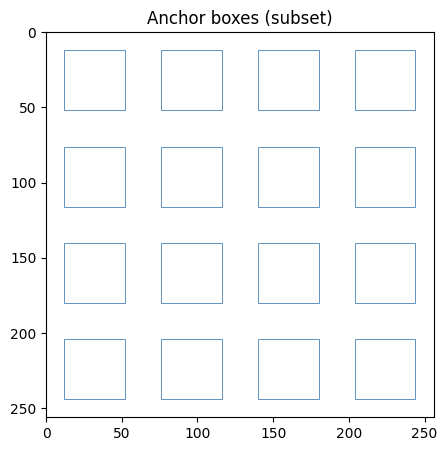

In [3]:
def make_anchors(img_size=256, grid=4, scales=(40, 80), ratios=(1.0, 0.5, 2.0)):
    step = img_size / grid
    anchors = []
    for i in range(grid):
        for j in range(grid):
            cx, cy = (j+0.5)*step, (i+0.5)*step
            for s in scales:
                for r in ratios:
                    w = s*np.sqrt(r); h = s/np.sqrt(r)
                    anchors.append([cx-w/2, cy-h/2, cx+w/2, cy+h/2])
    return np.array(anchors)

anchors = make_anchors()
print("generated", len(anchors), "anchors (=", 4*4, "cells x", 2, "scales x", 3, "ratios)")

fig, ax = plt.subplots(figsize=(5,5)); ax.set_xlim(0,256); ax.set_ylim(256,0)
for a in anchors[::6]:                                   # show a subset
    ax.add_patch(patches.Rectangle((a[0],a[1]), a[2]-a[0], a[3]-a[1], fill=False, edgecolor="steelblue", lw=0.6))
ax.set_title("Anchor boxes (subset)"); plt.show()

## 4. Non-Maximum Suppression (NMS)
A detector fires many overlapping boxes for one object. NMS keeps the highest-scoring box and removes others that overlap it beyond an IoU threshold.

kept boxes: [np.int64(3), np.int64(0)] ( 4 -> 2 )


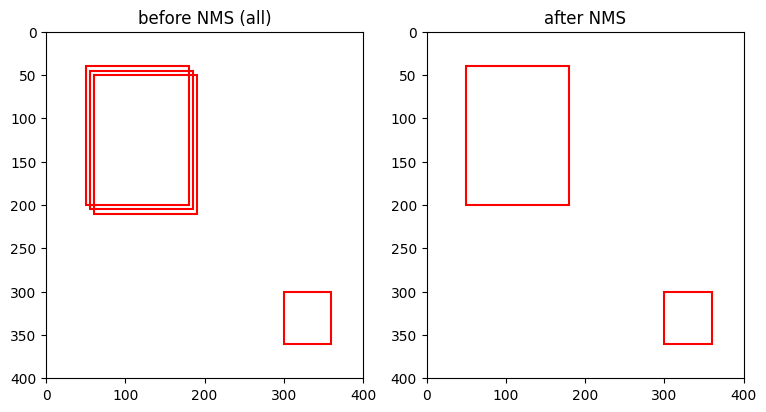

In [4]:
def nms(boxes, scores, iou_thresh=0.5):
    idxs = np.argsort(scores)[::-1]      # high score first
    keep = []
    while len(idxs) > 0:
        i = idxs[0]; keep.append(i)
        idxs = idxs[1:]
        idxs = np.array([j for j in idxs if iou(boxes[i], boxes[j]) < iou_thresh])
    return keep

boxes = np.array([[50,40,180,200],[60,50,190,210],[55,45,185,205],[300,300,360,360]])
scores = np.array([0.9, 0.8, 0.75, 0.95])
keep = nms(boxes, scores, 0.5)
print("kept boxes:", keep, "(", len(boxes), "->", len(keep), ")")

fig, axs = plt.subplots(1, 2, figsize=(9,4.5))
for ax, title, sel in [(axs[0],"before NMS (all)", range(len(boxes))), (axs[1],"after NMS", keep)]:
    ax.set_xlim(0,400); ax.set_ylim(400,0); ax.set_title(title)
    for k in sel:
        ax.add_patch(patches.Rectangle((boxes[k][0],boxes[k][1]), boxes[k][2]-boxes[k][0], boxes[k][3]-boxes[k][1], fill=False, edgecolor="red", lw=1.5))
plt.show()

## 5. Putting it together — a mini detection pipeline
The five stages from the doc: preprocess → feature/anchor generation → predict (here, simulated scores) → threshold → NMS.

In [5]:
np.random.seed(0)
cand = anchors[np.random.choice(len(anchors), 20, replace=False)]
sim_scores = np.random.rand(len(cand))
# 1) confidence threshold
mask = sim_scores > 0.5
cand, sim_scores = cand[mask], sim_scores[mask]
# 2) NMS
final = nms(cand, sim_scores, 0.3)
print(f"{len(anchors)} anchors -> {mask.sum()} above threshold -> {len(final)} final detections")

96 anchors -> 8 above threshold -> 7 final detections
